In [10]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2

from pathlib import Path
from tensorflow import keras
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import classification_report
from IPython.display import display
from tqdm.notebook import tqdm

SEED = 42
IMG_SIZE = (224, 224)

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

CLASS_TO_INDEX = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

# Project paths
PROJECT_DIR = Path.cwd()

ORIGINAL_TEST_DIR = PROJECT_DIR / "data" / "Testing"

ROI_TEST_DIR = (
    PROJECT_DIR
    / "outputs"
    / "notebook_04"
    / "roi_cropped"
    / "Testing"
)

ORIGINAL_MODEL_PATH = (
    PROJECT_DIR
    / "outputs"
    / "notebook_05"
    / "models"
    / "original"
    / "best_model.keras"
)

ROI_MODEL_PATH = (
    PROJECT_DIR
    / "outputs"
    / "notebook_05"
    / "models"
    / "roi_cropped"
    / "best_model.keras"
)

OUTPUT_DIR = PROJECT_DIR / "outputs" / "notebook_06"

ORIGINAL_OUTPUT_DIR = OUTPUT_DIR / "original"
ROI_OUTPUT_DIR = OUTPUT_DIR / "roi_cropped"

ORIGINAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ROI_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Project directory:", PROJECT_DIR)
print("Output directory:", OUTPUT_DIR)



TensorFlow: 2.21.0
Project directory: e:\SEM5\ERA\ERA_Project\Brain_Tumor
Output directory: e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_06


In [11]:
required_paths = [
    ORIGINAL_TEST_DIR,
    ROI_TEST_DIR,
    ORIGINAL_MODEL_PATH,
    ROI_MODEL_PATH
]

for path in required_paths:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path}")

if not all(path.exists() for path in required_paths):
    raise FileNotFoundError(
        "One or more paths are incorrect. "
        "Check the paths in Cell 1."
    )

original_model = keras.models.load_model(
    ORIGINAL_MODEL_PATH,
    compile=False
)

roi_model = keras.models.load_model(
    ROI_MODEL_PATH,
    compile=False
)

print("\nBoth models loaded successfully.")

print("\nOriginal model:")
original_model.summary()

print("\nROI model:")
roi_model.summary()



FOUND: e:\SEM5\ERA\ERA_Project\Brain_Tumor\data\Testing
FOUND: e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_04\roi_cropped\Testing
FOUND: e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_05\models\original\best_model.keras
FOUND: e:\SEM5\ERA\ERA_Project\Brain_Tumor\outputs\notebook_05\models\roi_cropped\best_model.keras

Both models loaded successfully.

Original model:


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 14,954,244 (57.05 MB)

 Non-trainable params: 9,159,040 (34.94 MB)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 14,954,244 (57.05 MB)

 Non-trainable params: 9,159,040 (34.94 MB)

In [12]:
def find_resnet_backbone(model):

    for layer in model.layers:
        if isinstance(layer, keras.Model):
            if "resnet" in layer.name.lower():
                return layer

    raise ValueError(
        "ResNet50 backbone not found. "
        "Check model.summary()."
    )


def create_gradcam_components(model):

    backbone = find_resnet_backbone(model)

    target_layer_name = "conv5_block3_out"

    target_layer = backbone.get_layer(
        target_layer_name
    )

    # Build a feature extractor using the nested backbone
    feature_extractor = keras.Model(
        inputs=backbone.inputs,
        outputs=target_layer.output,
        name=f"{backbone.name}_gradcam_features"
    )

    # Get classification layers after the backbone
    backbone_index = model.layers.index(backbone)

    classification_layers = model.layers[
        backbone_index + 1:
    ]

    print("Backbone:", backbone.name)
    print("Target layer:", target_layer.name)

    print("\nClassification layers:")

    for layer in classification_layers:
        print(layer.name)

    return feature_extractor, classification_layers


original_components = create_gradcam_components(
    original_model
)

roi_components = create_gradcam_components(
    roi_model
)

print("\nGrad-CAM components created successfully.")

Backbone: resnet50
Target layer: conv5_block3_out

Classification layers:
global_average_pooling2d
dropout
dense
dropout_1
dense_1
Backbone: resnet50
Target layer: conv5_block3_out

Classification layers:
global_average_pooling2d
dropout
dense
dropout_1
dense_1

Grad-CAM components created successfully.


In [13]:
def load_mri_image(image_path):
    """
    Load an MRI image and prepare it for ResNet50.
    """
    image = keras.utils.load_img(
        image_path,
        target_size=IMG_SIZE
    )

    image_array = keras.utils.img_to_array(image)

    model_input = np.expand_dims(
        image_array.copy(),
        axis=0
    )

    model_input = preprocess_input(model_input)

    return image_array.astype(np.uint8), model_input


def generate_gradcam(
    model,
    image_input,
    components,
    class_index=None
):

    feature_extractor, classification_layers = components

    backbone = find_resnet_backbone(model)

    target_layer = backbone.get_layer(
        "conv5_block3_out"
    )

    target_index = backbone.layers.index(target_layer)

    remaining_backbone_layers = backbone.layers[
        target_index + 1:
    ]

    image_tensor = tf.convert_to_tensor(
        image_input,
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        conv_outputs = feature_extractor(
            image_tensor,
            training=False
        )

        tape.watch(conv_outputs)

        x = conv_outputs

        # Replay remaining ResNet50 layers
        for layer in remaining_backbone_layers:

            if isinstance(layer, keras.layers.InputLayer):
                continue

            x = layer(x, training=False)

        # Apply classification head
        for layer in classification_layers:
            x = layer(x, training=False)

        predictions = x

        if class_index is None:
            class_index = tf.argmax(predictions[0])

        class_score = predictions[:, class_index]

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    if gradients is None:
        raise RuntimeError(
            "Gradients are None. "
            "The selected feature maps are not connected "
            "to the classification output."
        )

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_gradients,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = tf.math.divide_no_nan(
        heatmap,
        tf.reduce_max(heatmap)
    )

    return heatmap.numpy(), predictions.numpy()[0]



In [14]:
def collect_test_images(test_dir):

    records = []

    for class_name in CLASS_NAMES:

        class_dir = test_dir / class_name

        if not class_dir.exists():
            raise FileNotFoundError(
                f"Missing class directory: {class_dir}"
            )

        for image_path in sorted(class_dir.iterdir()):

            if image_path.suffix.lower() not in [
                ".jpg", ".jpeg", ".png", ".bmp"
            ]:
                continue

            records.append({
                "path": str(image_path),
                "filename": image_path.name,
                "class_name": class_name,
                "true_index": CLASS_TO_INDEX[class_name]
            })

    return pd.DataFrame(records)


original_test_df = collect_test_images(
    ORIGINAL_TEST_DIR
)

roi_test_df = collect_test_images(
    ROI_TEST_DIR
)

print("Original test images:", len(original_test_df))
print("ROI test images:", len(roi_test_df))

# Verify that both datasets contain corresponding files
original_keys = set(
    zip(original_test_df["class_name"], original_test_df["filename"])
)

roi_keys = set(
    zip(roi_test_df["class_name"], roi_test_df["filename"])
)

if original_keys != roi_keys:
    raise ValueError(
        "Original and ROI test filenames do not match. "
        "Check ROI extraction output before comparison."
    )

print("Corresponding test filenames verified.")



Original test images: 1600
ROI test images: 1600
Corresponding test filenames verified.


In [15]:
def predict_dataset(model, test_df):

    results = []

    for _, row in tqdm(
        test_df.iterrows(),
        total=len(test_df)
    ):

        _, image_input = load_mri_image(
            row["path"]
        )

        probabilities = model.predict(
            image_input,
            verbose=0
        )[0]

        predicted_index = int(
            np.argmax(probabilities)
        )

        results.append({
            "path": row["path"],
            "filename": row["filename"],
            "true_class": row["class_name"],
            "true_index": row["true_index"],
            "predicted_class": CLASS_NAMES[predicted_index],
            "predicted_index": predicted_index,
            "confidence": float(
                probabilities[predicted_index]
            ),
            "correct": (
                predicted_index == row["true_index"]
            )
        })

    return pd.DataFrame(results)


original_predictions = predict_dataset(
    original_model,
    original_test_df
)

roi_predictions = predict_dataset(
    roi_model,
    roi_test_df
)

original_predictions.to_csv(
    OUTPUT_DIR / "original_predictions.csv",
    index=False
)

roi_predictions.to_csv(
    OUTPUT_DIR / "roi_predictions.csv",
    index=False
)

print("Prediction files saved.")



  0%|          | 0/1600 [00:00<?, ?it/s]

  0%|          | 0/1600 [00:00<?, ?it/s]

Prediction files saved.


In [16]:
def select_examples(predictions, correct_count=2, incorrect_count=2):

    selected = []

    for class_name in CLASS_NAMES:

        class_data = predictions[
            predictions["true_class"] == class_name
        ]

        correct = class_data[
            class_data["correct"]
        ].sort_values(
            "confidence",
            ascending=False
        ).head(correct_count)

        incorrect = class_data[
            ~class_data["correct"]
        ].sort_values(
            "confidence",
            ascending=False
        ).head(incorrect_count)

        selected.extend(
            correct.to_dict("records")
        )

        selected.extend(
            incorrect.to_dict("records")
        )

    return selected


original_examples = select_examples(
    original_predictions
)

roi_examples = select_examples(
    roi_predictions
)

print("Original examples selected:", len(original_examples))
print("ROI examples selected:", len(roi_examples))



Original examples selected: 12
ROI examples selected: 14


In [17]:
def create_gradcam_overlay(
    original_image,
    heatmap,
    alpha=0.4
):

    # Resize heatmap to original image dimensions
    heatmap_resized = cv2.resize(
        heatmap,
        (
            original_image.shape[1],
            original_image.shape[0]
        )
    )

    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    colored_heatmap = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    colored_heatmap = cv2.cvtColor(
        colored_heatmap,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        original_image,
        1 - alpha,
        colored_heatmap,
        alpha,
        0
    )

    return overlay


def process_examples(
    model,
    components,
    examples,
    output_dir,
    model_name
):

    records = []

    for index, example in enumerate(
        tqdm(examples)
    ):

        image_path = example["path"]

        original_image, image_input = load_mri_image(
            image_path
        )

        true_index = example["true_index"]

        # Explain the predicted class
        predicted_index = example["predicted_index"]

        heatmap, probabilities = generate_gradcam(
            model,
            image_input,
            components,
            class_index=predicted_index
        )

        overlay = create_gradcam_overlay(
            original_image,
            heatmap
        )

        status = (
            "correct"
            if example["correct"]
            else "incorrect"
        )

        safe_filename = (
            f"{index:03d}_"
            f"{example['true_class']}_"
            f"{status}_"
            f"{Path(image_path).stem}"
        )

        # Save heatmap
        plt.imsave(
            output_dir / f"{safe_filename}_heatmap.png",
            heatmap,
            cmap="jet"
        )

        # Save overlay
        plt.imsave(
            output_dir / f"{safe_filename}_overlay.png",
            overlay
        )

        records.append({
            "model": model_name,
            "filename": example["filename"],
            "true_class": example["true_class"],
            "predicted_class": example["predicted_class"],
            "confidence": example["confidence"],
            "correct": example["correct"],
            "heatmap_path": str(
                output_dir / f"{safe_filename}_heatmap.png"
            ),
            "overlay_path": str(
                output_dir / f"{safe_filename}_overlay.png"
            )
        })

    return pd.DataFrame(records)


original_gradcam_results = process_examples(
    original_model,
    original_components,
    original_examples,
    ORIGINAL_OUTPUT_DIR,
    "Original"
)

roi_gradcam_results = process_examples(
    roi_model,
    roi_components,
    roi_examples,
    ROI_OUTPUT_DIR,
    "ROI-Cropped"
)

gradcam_results = pd.concat(
    [
        original_gradcam_results,
        roi_gradcam_results
    ],
    ignore_index=True
)

gradcam_results.to_csv(
    OUTPUT_DIR / "gradcam_results.csv",
    index=False
)

print("Grad-CAM generation completed.")



  0%|          | 0/12 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

Grad-CAM generation completed.


ORIGINAL MODEL


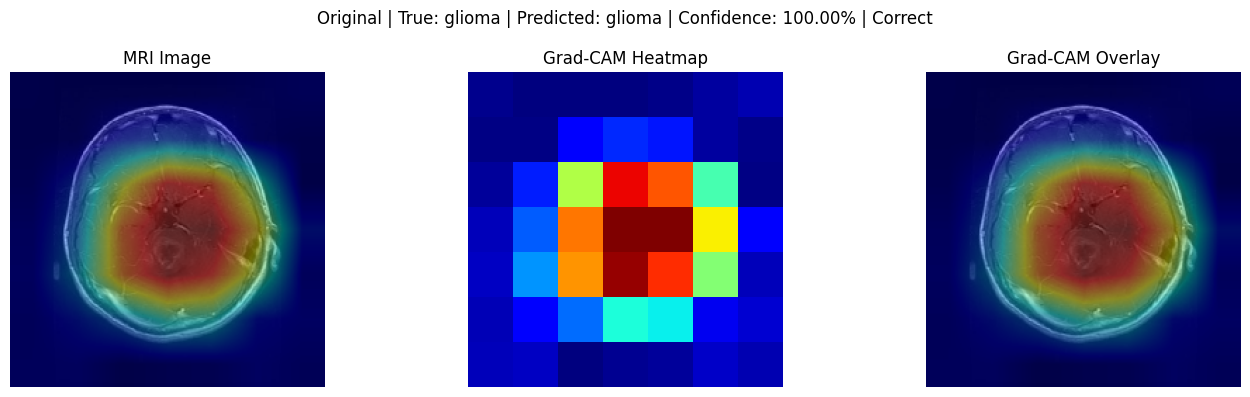

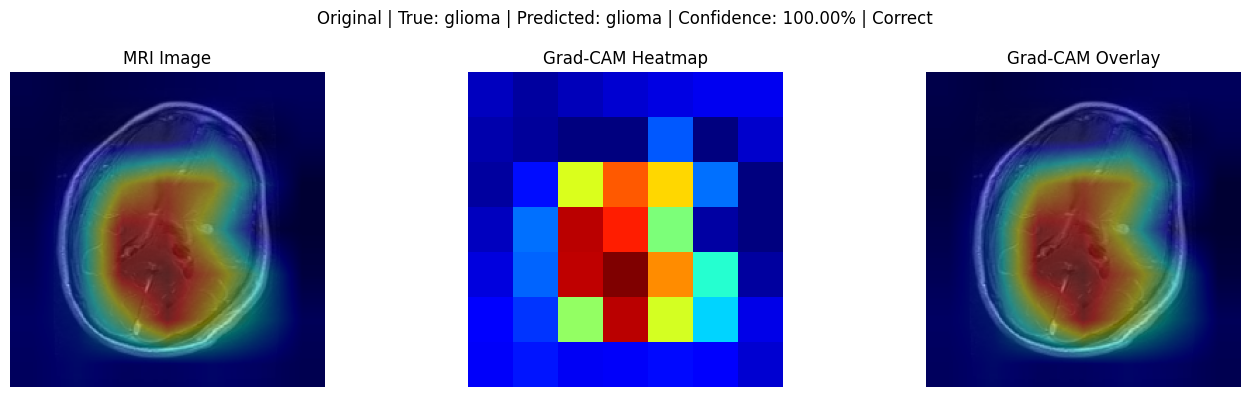

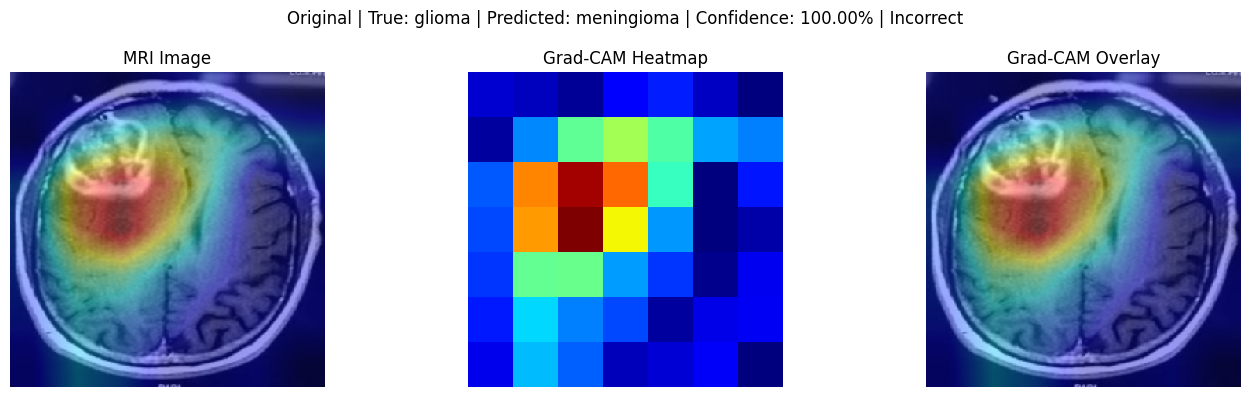

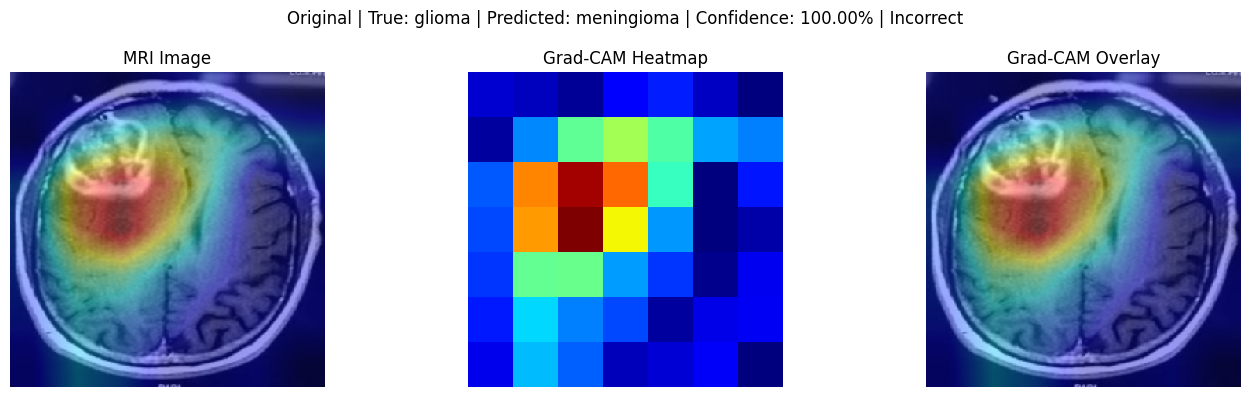

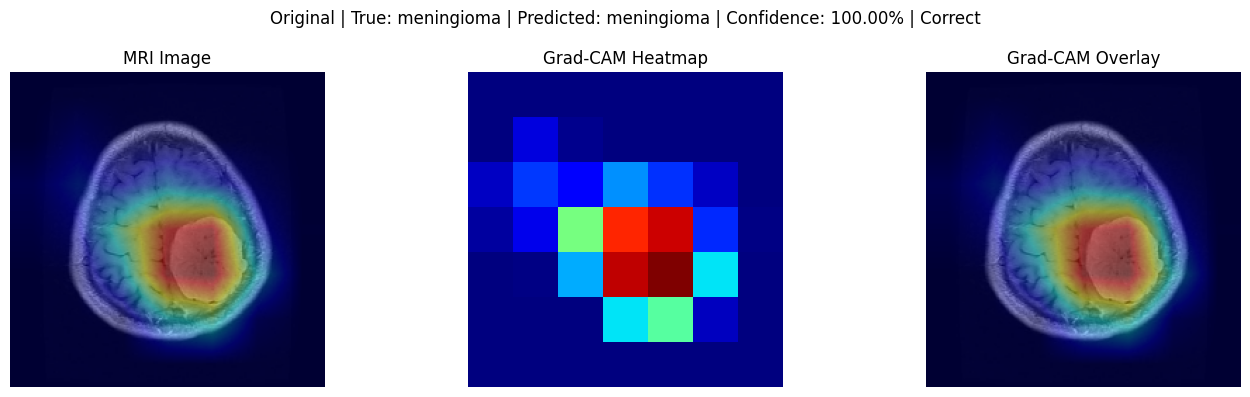

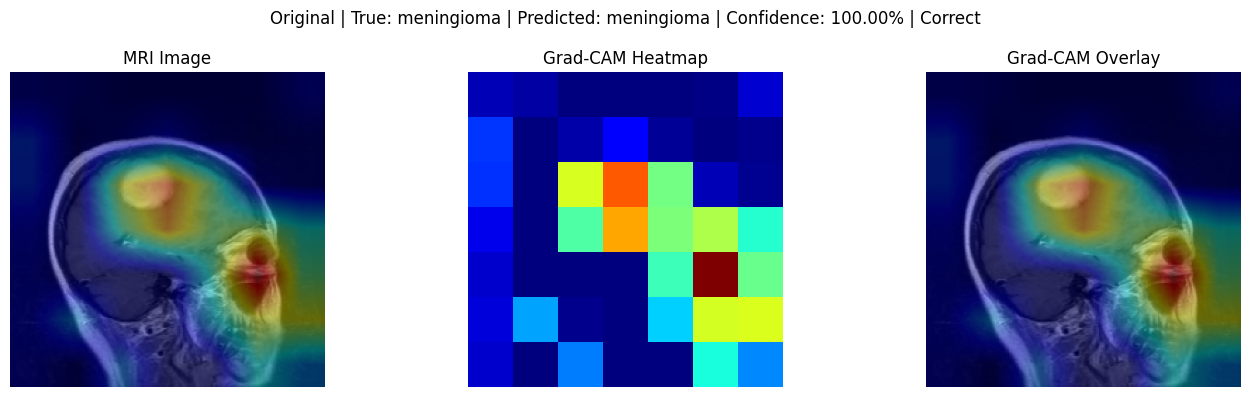

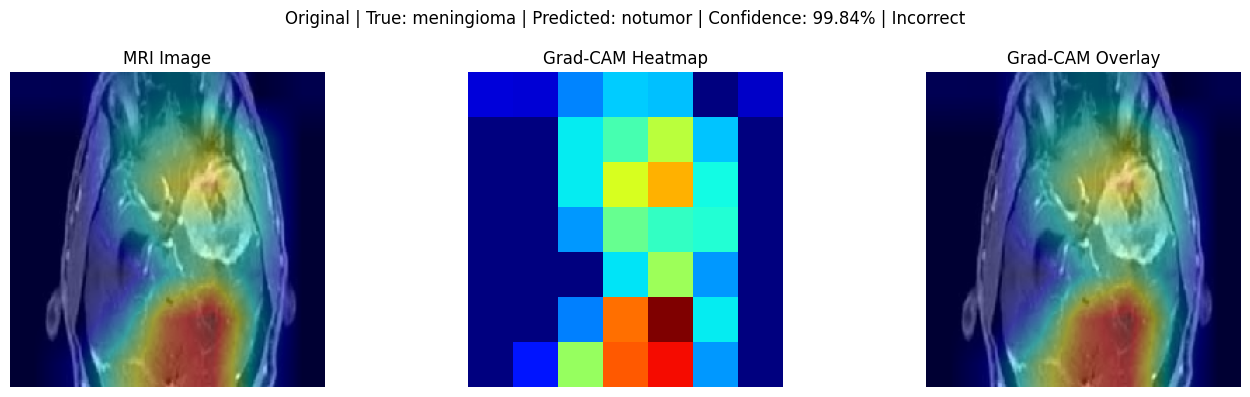

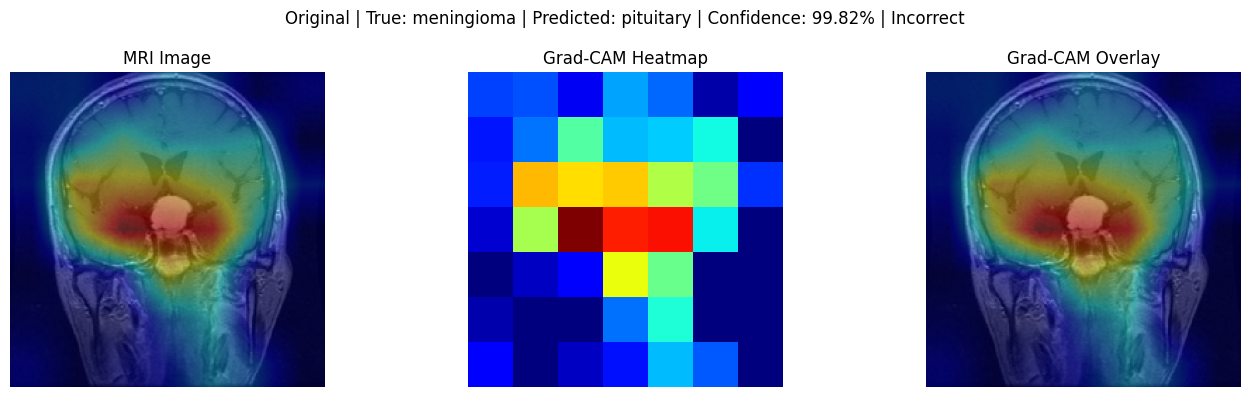

ROI-CROPPED MODEL


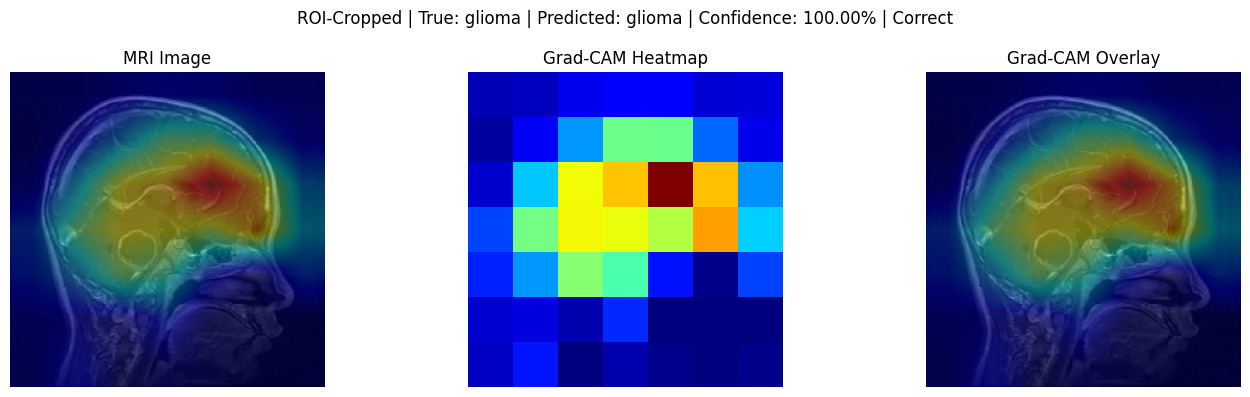

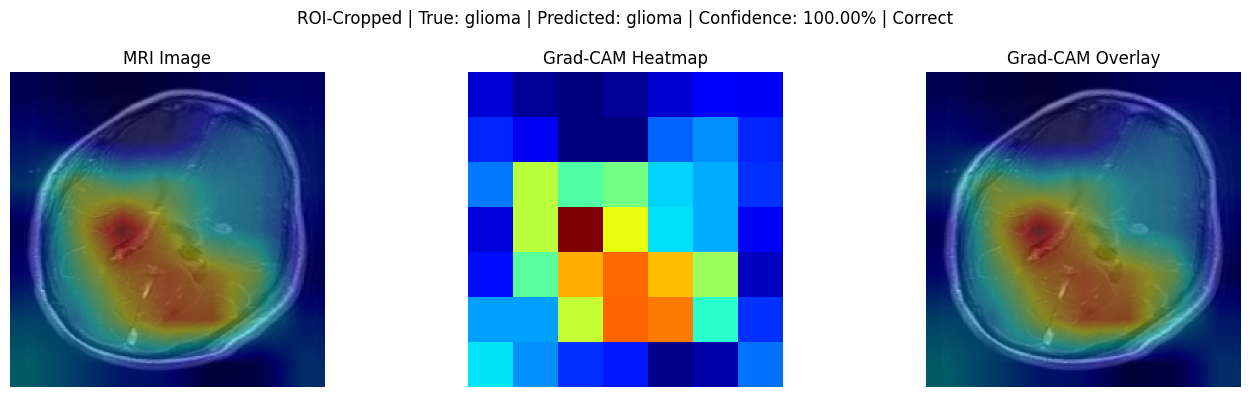

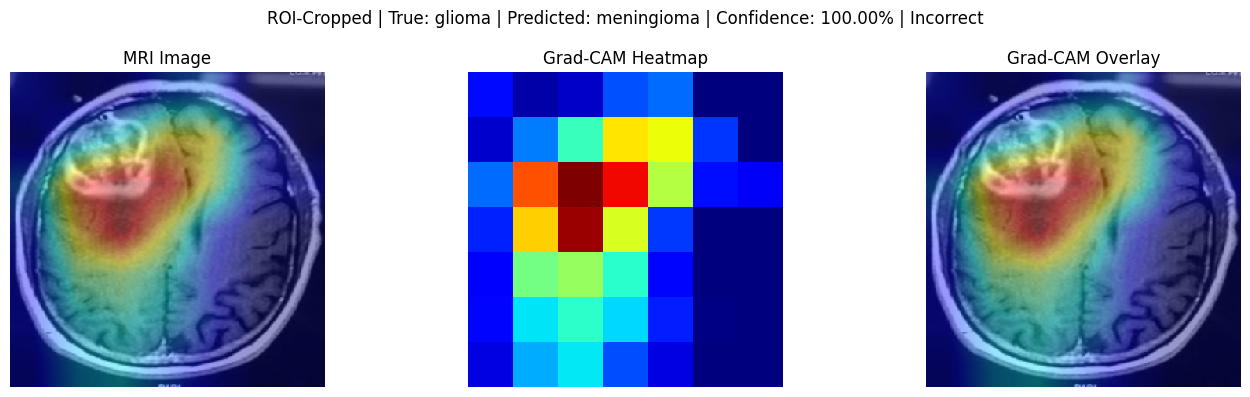

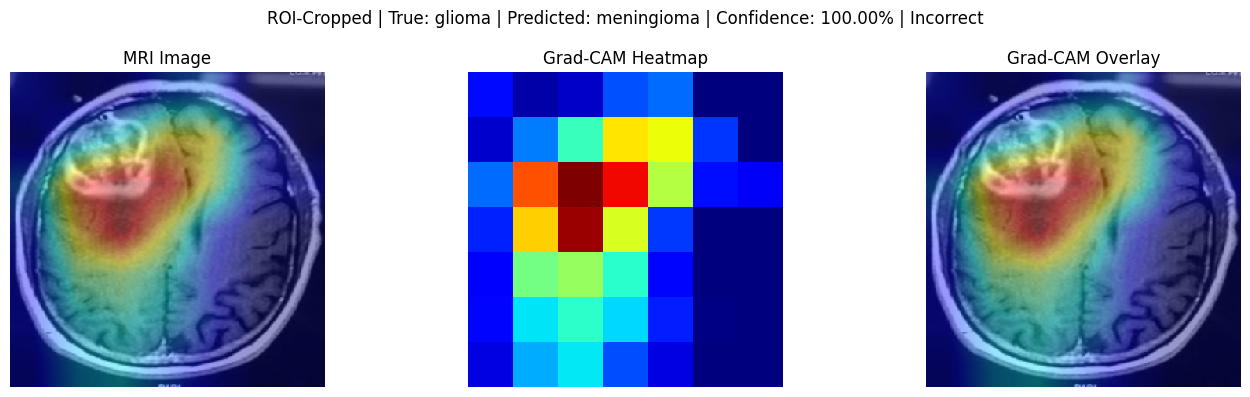

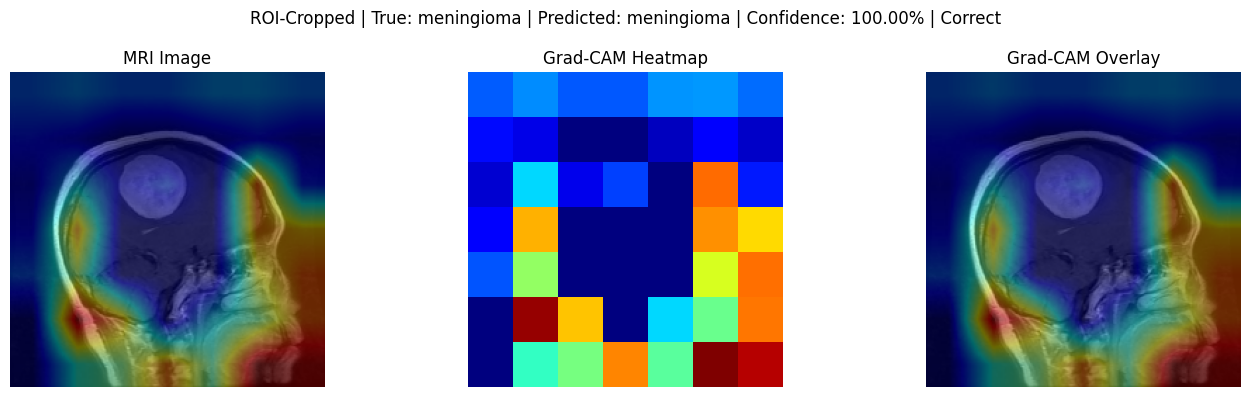

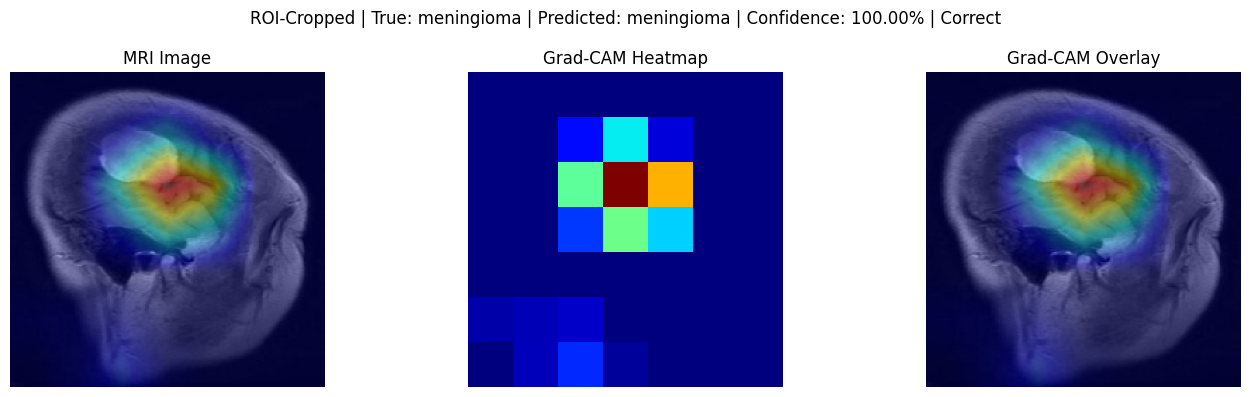

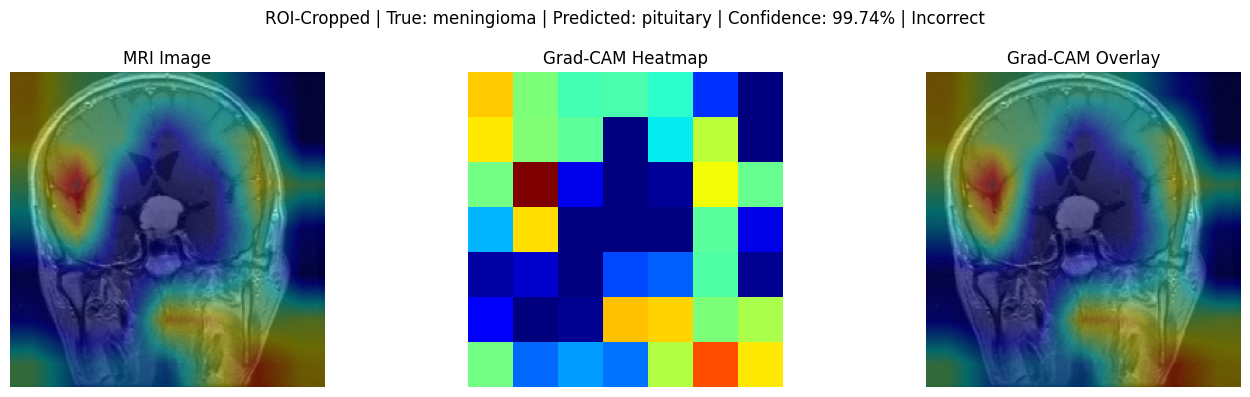

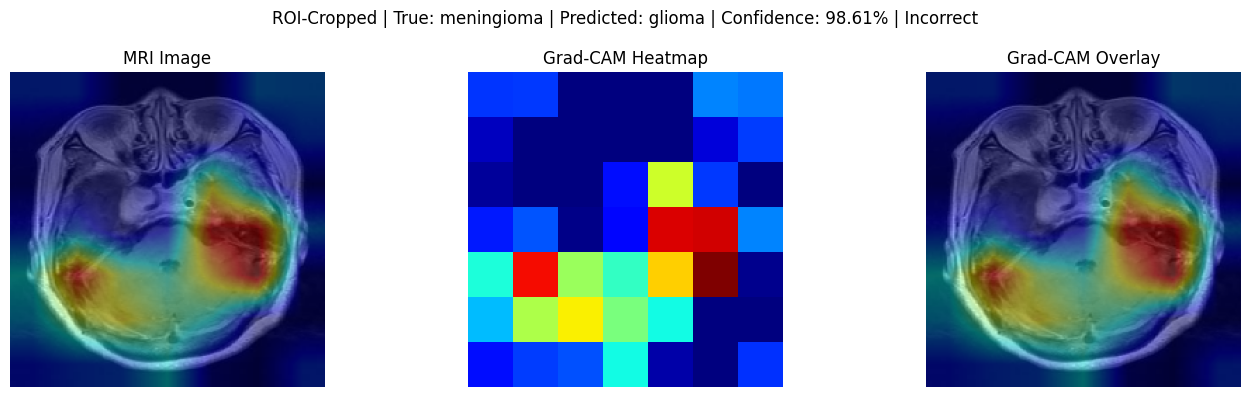

In [18]:
def display_gradcam_examples(
    results,
    number_of_examples=8
):

    subset = results.head(number_of_examples)

    for _, row in subset.iterrows():

        original_image, _ = load_mri_image(
            row["overlay_path"]
        )

        overlay = plt.imread(
            row["overlay_path"]
        )

        heatmap = plt.imread(
            row["heatmap_path"]
        )

        fig, axes = plt.subplots(
            1, 3,
            figsize=(14, 4)
        )

        axes[0].imshow(original_image)
        axes[0].set_title("MRI Image")

        axes[1].imshow(heatmap, cmap="jet")
        axes[1].set_title("Grad-CAM Heatmap")

        axes[2].imshow(overlay)
        axes[2].set_title("Grad-CAM Overlay")

        for ax in axes:
            ax.axis("off")

        status = (
            "Correct"
            if row["correct"]
            else "Incorrect"
        )

        fig.suptitle(
            f"{row['model']} | "
            f"True: {row['true_class']} | "
            f"Predicted: {row['predicted_class']} | "
            f"Confidence: {row['confidence']:.2%} | "
            f"{status}"
        )

        plt.tight_layout()
        plt.show()


print("ORIGINAL MODEL")
display_gradcam_examples(
    original_gradcam_results
)

print("ROI-CROPPED MODEL")
display_gradcam_examples(
    roi_gradcam_results
)



In [19]:
comparison = gradcam_results.groupby(
    ["model", "true_class", "correct"]
).size().reset_index(name="image_count")

display(comparison)

print("\nCorrect and incorrect examples:")
display(
    gradcam_results[
        [
            "model",
            "filename",
            "true_class",
            "predicted_class",
            "confidence",
            "correct"
        ]
    ]
)



,model,true_class,correct,image_count
0,Original,glioma,False,2
1,Original,glioma,True,2
2,Original,meningioma,False,2
3,Original,meningioma,True,2
4,Original,notumor,True,2
5,Original,pituitary,True,2
6,ROI-Cropped,glioma,False,2
7,ROI-Cropped,glioma,True,2
8,ROI-Cropped,meningioma,False,2
9,ROI-Cropped,meningioma,True,2



Correct and incorrect examples:


,model,filename,true_class,predicted_class,confidence,correct
0,Original,Te-gl_9.jpg,glioma,glioma,1.000000,True
1,Original,Te-gl_10.jpg,glioma,glioma,1.000000,True
2,Original,Te-gl_171.jpg,glioma,meningioma,0.999990,False
3,Original,Te-gl_228.jpg,glioma,meningioma,0.999990,False
4,Original,Te-me_58.jpg,meningioma,meningioma,1.000000,True
5,Original,Te-aug-me_82.jpg,meningioma,meningioma,1.000000,True
6,Original,Te-me_186.jpg,meningioma,notumor,0.998430,False
7,Original,Te-me_114.jpg,meningioma,pituitary,0.998231,False
8,Original,Te-no_10.jpg,notumor,notumor,1.000000,True
9,Original,Te-no_102.jpg,notumor,notumor,1.000000,True


In [20]:
print("Notebook 06 completed.")

print("\nGenerated files:")

for path in OUTPUT_DIR.rglob("*"):
    if path.is_file():
        print(path.relative_to(PROJECT_DIR))

        

Notebook 06 completed.

Generated files:
outputs\notebook_06\gradcam_results.csv
outputs\notebook_06\original_predictions.csv
outputs\notebook_06\roi_predictions.csv
outputs\notebook_06\original\000_glioma_correct_Te-gl_9_heatmap.png
outputs\notebook_06\original\000_glioma_correct_Te-gl_9_overlay.png
outputs\notebook_06\original\001_glioma_correct_Te-gl_10_heatmap.png
outputs\notebook_06\original\001_glioma_correct_Te-gl_10_overlay.png
outputs\notebook_06\original\002_glioma_incorrect_Te-gl_171_heatmap.png
outputs\notebook_06\original\002_glioma_incorrect_Te-gl_171_overlay.png
outputs\notebook_06\original\003_glioma_incorrect_Te-gl_228_heatmap.png
outputs\notebook_06\original\003_glioma_incorrect_Te-gl_228_overlay.png
outputs\notebook_06\original\004_meningioma_correct_Te-me_58_heatmap.png
outputs\notebook_06\original\004_meningioma_correct_Te-me_58_overlay.png
outputs\notebook_06\original\005_meningioma_correct_Te-aug-me_82_heatmap.png
outputs\notebook_06\original\005_meningioma_corre